**15.071 The AI Edge** · Proyecto 1 · Fall 2026 · Felipe (`friosf`) — modelo 3 de MEMORIA.md

---

# Custom Transformer (v5): clasificación de intenciones de Sole Smart Actions

Este notebook entrena el **Transformer propio desde cero** (modelo 3 de MEMORIA) con **el mismo dataset y el mismo protocolo que el notebook v5 de Ricardo** (`01_sole_intent_classifier_v5.ipynb`), para que su fila se pueda agregar directamente a la tabla final del equipo junto a DistilBERT.

**Protocolo compartido (igual que Ricardo v5):**

| Decisión | Valor |
|---|---|
| Datos | `Sole_Smart_Actions_Intent_Training_v5_Deduplicated.xlsx`: 997 duplicados reemplazados por comandos nuevos; cero duplicados |
| Muestra | 2,700 comandos: 8 intenciones core + UNKNOWN_INTENT (CHECK_SPENDING aparte) |
| Splits | Los del Excel: train 1,920 · validation 240 · test 240; paso de eliminación de duplicados (aquí no elimina nada) |
| No soportados | 300 UNKNOWN divididos al azar: 150 para el umbral y 150 reservados (`RandomState(1234)`) |
| Selección | Se entrena con train; gana la mayor **accuracy de validation**; empates → menor **log loss** de validation |
| Modelo final | Se **reentrena en train + validation** con los hiperparámetros y el número de épocas elegidos; ese es el que se evalúa en test |
| Calibración | **Temperature scaling** ajustado en validation con la copia de solo train y aplicado sin cambios a la copia reentrenada |
| Compuerta | Umbral que maximiza el valor en dólares en validation + 150 UNKNOWN (copia de solo train, calibrada); se aplica sin cambios en test + 150 UNKNOWN reservados (copia reentrenada, calibrada); mismos costos |
| Métricas | Accuracy y macro F1 de test, test "unseen", parámetros, latencia de un comando de punta a punta, valor anual |

## Setup

In [1]:
import os
import re
import time
import gzip
import random
import urllib.request
from pathlib import Path
from collections import Counter

DATA_FILE = Path("data") / "raw" / "Sole_Smart_Actions_Intent_Training_v5_Deduplicated.xlsx"
ROOT = Path.cwd()
while not (ROOT / DATA_FILE).exists():
    if ROOT.parent == ROOT:
        raise RuntimeError("No encuentro la carpeta del proyecto: fija ROOT a mano.")
    ROOT = ROOT.parent
DATA_PATH = ROOT / DATA_FILE
REPORTS = ROOT / "reports"
REPORTS.mkdir(exist_ok=True)
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar

from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow import keras
from keras import layers, ops

from IPython.display import display

import warnings
warnings.filterwarnings("ignore")
np.seterr(over="ignore", divide="ignore", invalid="ignore")

print("Proyecto:", ROOT)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)

Proyecto: <local path>
TensorFlow 2.21.0 | Keras 3.15.1


In [2]:
SEED = 1234

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CORE_INTENTS = [
    "TRANSFER_MONEY", "CHECK_BALANCE", "VIEW_TRANSACTIONS", "WITHDRAW_MONEY",
    "BILL_PAY", "HELP_SUPPORT", "MANAGE_CONTACTS", "VIEW_GROUP",
]
STRETCH_INTENT = "CHECK_SPENDING"
UNKNOWN = "UNKNOWN_INTENT"

INCLUDE_STRETCH = False
CLASSES = CORE_INTENTS + ([STRETCH_INTENT] if INCLUDE_STRETCH else [])
MONEY_MOVING = ["TRANSFER_MONEY", "WITHDRAW_MONEY", "BILL_PAY"]

ACCENT = "#0072B2"
ACCENT_LIGHT = "#CFE2F3"
ACCENT_DARK = "#00405F"
WARNING = "#D55E00"
INK = "#0B0B0B"
INK_SECONDARY = "#52514E"

FONTSIZE = 13
plt.rcParams.update({"font.size": FONTSIZE, "axes.labelsize": FONTSIZE,
                     "xtick.labelsize": FONTSIZE - 1, "ytick.labelsize": FONTSIZE - 1,
                     "legend.fontsize": FONTSIZE - 1})

## 1. El dataset v5

Mismo código que Ricardo: carga, splits del Excel y división al azar de los no soportados.

In [3]:
raw = pd.read_excel(DATA_PATH, sheet_name="Training Data")

dat = (
    raw.assign(text=lambda d: d["text"].astype(str).str.replace(r"\s+", " ", regex=True).str.strip())
       .loc[lambda d: d["intent"].isin(CLASSES + [UNKNOWN])]
       .reset_index(drop=True)
)

print(f"Todos los comandos: {len(raw):,}")
print(f"Muestra de trabajo: {len(dat):,} ({len(CLASSES)} intenciones soportadas + {UNKNOWN})")
display(pd.crosstab(dat["intent"], dat["split"], margins=True, margins_name="Total")
          .reindex(CLASSES + [UNKNOWN, "Total"])[["train", "validation", "test", "evaluation_only", "Total"]])


def make_splits(data):
    # Etiquetas enteras y los índices de cada subconjunto, según el split del propio dataset
    labels = np.array([CLASSES.index(i) if i in CLASSES else -1 for i in data["intent"]])
    split = data["split"].values
    train = np.where((split == "train") & (labels >= 0))[0]
    val = np.where((split == "validation") & (labels >= 0))[0]
    test = np.where((split == "test") & (labels >= 0))[0]
    # No soportados: la mitad para el umbral, la otra mitad reservada
    unknown = np.where(labels == -1)[0]
    shuffled = np.random.RandomState(SEED).permutation(unknown)
    unk_tune = np.sort(shuffled[: len(unknown) // 2])
    unk_hold = np.sort(shuffled[len(unknown) // 2:])
    return labels, data["text"].values, train, val, test, unknown, unk_tune, unk_hold


# Eliminación de duplicados como en las Lectures 10-12 (en v5 no elimina nada): se conserva la copia de train
SPLIT_PRIORITY = {"train": 0, "validation": 1, "test": 2, "evaluation_only": 3}
before = len(dat)
dat = (dat.assign(key=lambda d: d["text"].str.lower().str.strip(),
                  priority=lambda d: d["split"].map(SPLIT_PRIORITY))
          .sort_values("priority", kind="stable")
          .drop_duplicates(subset="key")
          .sort_index()
          .drop(columns=["key", "priority"])
          .reset_index(drop=True))
print(f"\nDuplicados eliminados: {before - len(dat):,} -> muestra de trabajo: {len(dat):,}")

y, texts, train_idx, val_idx, test_idx, unknown_idx, unk_tune_idx, unk_hold_idx = make_splits(dat)
gate_val_idx = np.concatenate([val_idx, unk_tune_idx])
gate_test_idx = np.concatenate([test_idx, unk_hold_idx])

normalized = dat["text"].str.lower().str.strip()
seen_in_train = normalized.isin(set(normalized.iloc[train_idx])).values
test_unseen_idx = test_idx[~seen_in_train[test_idx]]

print(f"Train: {len(train_idx):,} | Validation: {len(val_idx):,} + {len(unk_tune_idx)} no soportados | "
      f"Test: {len(test_idx):,} + {len(unk_hold_idx)} no soportados")
print(f"Test también en train: {seen_in_train[test_idx].sum()} | Validation también en train: {seen_in_train[val_idx].sum()}")

Todos los comandos: 3,000
Muestra de trabajo: 2,700 (8 intenciones soportadas + UNKNOWN_INTENT)


split,train,validation,test,evaluation_only,Total
intent,,,,,
TRANSFER_MONEY,240,30,30,0,300
CHECK_BALANCE,240,30,30,0,300
VIEW_TRANSACTIONS,240,30,30,0,300
WITHDRAW_MONEY,240,30,30,0,300
BILL_PAY,240,30,30,0,300
HELP_SUPPORT,240,30,30,0,300
MANAGE_CONTACTS,240,30,30,0,300
VIEW_GROUP,240,30,30,0,300
UNKNOWN_INTENT,0,0,0,300,300



Duplicados eliminados: 0 -> muestra de trabajo: 2,700
Train: 1,920 | Validation: 240 + 150 no soportados | Test: 240 + 150 no soportados
Test también en train: 0 | Validation también en train: 0


In [4]:
def simple_words(text):
    return re.sub(r"[^\w\s]", " ", text.lower()).split()


def distinctive_words(texts_subset, labels_subset, category, min_count=8, top_n=10, smoothing=1.0):
    in_class = Counter(w for t, l in zip(texts_subset, labels_subset) if l == category for w in simple_words(t))
    out_class = Counter(w for t, l in zip(texts_subset, labels_subset) if l != category for w in simple_words(t))
    n_in, n_out = sum(in_class.values()), sum(out_class.values())
    rows = []
    for word, count in in_class.items():
        if not word.isalpha() or len(word) < 3 or count + out_class[word] < min_count:
            continue
        rows.append((word, ((count + smoothing) / n_in) / ((out_class[word] + smoothing) / n_out), count))
    return (pd.DataFrame(rows, columns=["word", "lift", "count"])
            .sort_values("lift", ascending=False).head(top_n).reset_index(drop=True))


train_labels = [CLASSES[k] for k in y[train_idx]]
for intent in CLASSES:
    print(f"{intent:18s} | {', '.join(distinctive_words(texts[train_idx], train_labels, intent, top_n=6)['word'])}")

TRANSFER_MONEY     | put, friend, fiji, send, transfer, ana
CHECK_BALANCE      | there, available, tell, current, left, spend
VIEW_TRANSACTIONS  | payments, did, transactions, transfers, incoming, give
WITHDRAW_MONEY     | withdraw, out, take, collect, withdrawal, cash
BILL_PAY           | bill, water, provider, settle, internet, electricity
HELP_SUPPORT       | with, pin, support, report, access, forgot
MANAGE_CONTACTS    | add, contacts, recipient, delete, save, remove
VIEW_GROUP         | group, contributions, contributed, family, village, our


## 2. Protocolo de evaluación y los dos benchmarks de Ricardo

Las funciones `register`, `validation_scores`, `select_best`, `test_scores` y `running_summary` son las del notebook de Ricardo. Cada modelo registra **dos** juegos de probabilidades para todos los comandos: la copia de **solo train** (validation honesta: calibración y umbral) y la copia **reentrenada en train + validation** (todas las cifras de test).

Volvemos a correr sus dos benchmarks como **control**: si los datos y los splits son idénticos, deben dar exactamente sus números (mayoría 0.125, regla de palabras clave 0.733 en test).

In [5]:
ABSTAIN = -2
REFIT_IDX = np.concatenate([train_idx, val_idx])
FINALISTS = {}
PREDICTORS = {}


def predict_labels(proba):
    pred = proba.argmax(axis=1)
    return np.where(np.isclose(proba.max(axis=1), proba.min(axis=1)), ABSTAIN, pred)


def log_loss_on(proba, subset):
    return float(-np.mean(np.log(np.clip(proba[subset, y[subset]], 1e-7, 1.0))))


def validation_scores(proba):
    pred = predict_labels(proba)
    return {"Train accuracy": accuracy_score(y[train_idx], pred[train_idx]),
            "Validation accuracy": accuracy_score(y[val_idx], pred[val_idx]),
            "Validation log loss": log_loss_on(proba, val_idx)}


def select_best(table):
    # Mayor accuracy de validation; empates -> menor log loss de validation
    return table.sort_values(["Validation accuracy", "Validation log loss"], ascending=[False, True]).iloc[0]


def selection_reason(table, chosen):
    best = table["Validation accuracy"].max()
    tied = int(np.isclose(table["Validation accuracy"], best).sum())
    close = int((table["Validation accuracy"] >= best - 1 / len(val_idx) - 1e-9).sum())
    reason = f"highest validation accuracy ({best:.3f}) among {len(table)} configurations"
    if tied > 1:
        reason += (f"; {tied} configurations tied, and this one has the lowest validation "
                   f"log loss ({chosen['Validation log loss']:.3f})")
    if close > tied:
        reason += (f"; {close} configurations are within one validation command of the best, "
                   f"so the differences among them are within noise")
    return reason


def test_scores(proba):
    pred = predict_labels(proba)
    return {"Test accuracy": accuracy_score(y[test_idx], pred[test_idx]),
            "Test accuracy (unseen)": accuracy_score(y[test_unseen_idx], pred[test_unseen_idx]),
            "Test macro F1": f1_score(y[test_idx], pred[test_idx], labels=list(range(len(CLASSES))),
                                      average="macro", zero_division=0)}


def register(name, proba, configuration, why, parameters, latency_ms, predictor,
             fit_seconds=None, kind="Model", proba_final=None):
    proba_final = proba if proba_final is None else proba_final
    for p in (proba, proba_final):
        assert p.shape == (len(texts), len(CLASSES))
    FINALISTS[name] = dict(proba=proba, proba_final=proba_final, configuration=configuration, why=why,
                           kind=kind, parameters=parameters, latency_ms=latency_ms, fit_seconds=fit_seconds)
    PREDICTORS[name] = predictor
    scores, test = validation_scores(proba), test_scores(proba_final)
    print(f"Final configuration — {name}")
    print(f"  Chosen:      {configuration}")
    print(f"  Why:         {why}")
    print(f"  Validation:  accuracy {scores['Validation accuracy']:.3f}, log loss {scores['Validation log loss']:.3f} "
          f"(training accuracy {scores['Train accuracy']:.3f})")
    print(f"  Deployment:  {parameters:,} parameters, {latency_ms:.2f} ms per command")
    print(f"  Test (refit on training + validation): accuracy {test['Test accuracy']:.3f}, unseen commands "
          f"{test['Test accuracy (unseen)']:.3f}, macro F1 {test['Test macro F1']:.3f}")


def running_summary():
    rows = [{"Model": name, "Type": f["kind"],
             "Validation accuracy": validation_scores(f["proba"])["Validation accuracy"],
             **test_scores(f["proba_final"]), "Parameters": f["parameters"],
             "Latency (ms)": f["latency_ms"], "Fit time (s)": f["fit_seconds"]}
            for name, f in FINALISTS.items()]
    return (pd.DataFrame(rows).style
            .format({"Validation accuracy": "{:.3f}", "Test accuracy": "{:.3f}", "Test accuracy (unseen)": "{:.3f}",
                     "Test macro F1": "{:.3f}", "Parameters": "{:,.0f}", "Latency (ms)": "{:.2f}",
                     "Fit time (s)": "{:.1f}"}, na_rep="—")
            .hide(axis="index"))


def measure_latency(predict_one, n=100):
    sample = test_idx[:n]
    predict_one(sample[0])
    started = time.perf_counter()
    for i in sample:
        predict_one(i)
    return 1000 * (time.perf_counter() - started) / len(sample)

In [6]:
majority_class = int(pd.Series(y[train_idx]).mode()[0])
majority_proba = np.zeros((len(dat), len(CLASSES)))
majority_proba[:, majority_class] = 1.0


def keyword_lists(top_n, fit_idx=None):
    fit_idx = train_idx if fit_idx is None else fit_idx
    labels = [CLASSES[k] for k in y[fit_idx]]
    return {intent: distinctive_words(texts[fit_idx], labels, intent, top_n=top_n)["word"].tolist() for intent in CLASSES}


def keyword_rule(text, keywords):
    words = set(simple_words(text))
    hits = np.array([len(words & set(keywords[intent])) for intent in CLASSES])
    proba = np.full(len(CLASSES), 1.0 / len(CLASSES))
    if hits.max() > 0 and (hits == hits.max()).sum() == 1:
        proba = np.zeros(len(CLASSES))
        proba[hits.argmax()] = 1.0
    return proba


KEYWORD_GRID = [3, 5, 10, 15, 20]
keyword_rows, keyword_proba = [], {}
for top_n in KEYWORD_GRID:
    keywords = keyword_lists(top_n)
    keyword_proba[top_n] = np.vstack([keyword_rule(t, keywords) for t in texts])
    keyword_rows.append({"Keywords per intent": top_n, **validation_scores(keyword_proba[top_n])})
keyword_results = pd.DataFrame(keyword_rows)

chosen = select_best(keyword_results)
KEYWORD_TOP_N = int(chosen["Keywords per intent"])
KEYWORDS = keyword_lists(KEYWORD_TOP_N, REFIT_IDX)
keyword_final = np.vstack([keyword_rule(t, KEYWORDS) for t in texts])
majority_final_class = int(pd.Series(y[REFIT_IDX]).mode()[0])
majority_final = np.zeros((len(dat), len(CLASSES)))
majority_final[:, majority_final_class] = 1.0

register(f"Always predict '{CLASSES[majority_final_class]}'", majority_proba,
         configuration=f"always the most common intent ({CLASSES[majority_final_class]})",
         why="the floor any model must beat", parameters=0, latency_ms=0.0,
         predictor=lambda text: majority_final[0], kind="Benchmark", proba_final=majority_final)
print()
register("Keyword rule", keyword_proba[KEYWORD_TOP_N],
         configuration=f"{KEYWORD_TOP_N} highest-lift words per intent; abstains when no keyword matches or intents tie",
         why=selection_reason(keyword_results, chosen), parameters=sum(len(v) for v in KEYWORDS.values()),
         latency_ms=measure_latency(lambda i: keyword_rule(texts[i], KEYWORDS)),
         predictor=lambda text: keyword_rule(text, KEYWORDS), kind="Benchmark", proba_final=keyword_final)

control = test_scores(keyword_final)["Test accuracy"]
print(f"\nControl: regla de palabras clave en test = {control:.3f} (Ricardo v5: 0.733)")
running_summary()

Final configuration — Always predict 'TRANSFER_MONEY'
  Chosen:      always the most common intent (TRANSFER_MONEY)
  Why:         the floor any model must beat
  Validation:  accuracy 0.125, log loss 14.103 (training accuracy 0.125)
  Deployment:  0 parameters, 0.00 ms per command
  Test (refit on training + validation): accuracy 0.125, unseen commands 0.125, macro F1 0.028

Final configuration — Keyword rule
  Chosen:      20 highest-lift words per intent; abstains when no keyword matches or intents tie
  Why:         highest validation accuracy (0.804) among 5 configurations
  Validation:  accuracy 0.804, log loss 2.162 (training accuracy 0.796)
  Deployment:  160 parameters, 0.04 ms per command
  Test (refit on training + validation): accuracy 0.733, unseen commands 0.733, macro F1 0.770

Control: regla de palabras clave en test = 0.733 (Ricardo v5: 0.733)


Model,Type,Validation accuracy,Test accuracy,Test accuracy (unseen),Test macro F1,Parameters,Latency (ms),Fit time (s)
Always predict 'TRANSFER_MONEY',Benchmark,0.125,0.125,0.125,0.028,0,0.00,—
Keyword rule,Benchmark,0.804,0.733,0.733,0.770,160,0.04,—


## 3. Del texto a los tokens

Como en las Lectures 11-12, `TextVectorization` se aprende con los comandos de ajuste y no hace stemming ni quita palabras funcionales. Igual que Ricardo hace con las palabras clave de su regla, **todo lo aprendido se vuelve a aprender al reentrenar en train + validation**: el vocabulario y la matriz GloVe de la copia reentrenada salen de train + validation; los de la copia de solo train, solo de train. El test nunca entra en el vocabulario.

GloVe 100d se descarga una sola vez (~130 MB) y se guarda el subconjunto con las 40,000 palabras más frecuentes del inglés más las del vocabulario de train + validation.

In [7]:
MAX_LENGTH = 16       # tokens por comando: el más largo de v5 tiene 12 palabras
MAX_TOKENS = 2000
EMBEDDING_DIM = 100
GLOVE_URL = ("https://huggingface.co/datasets/SLU-CSCI4750/glove.6B.100d.txt"
             "/resolve/main/glove.6B.100d.txt.gz")
GLOVE_CACHE = ROOT / "data" / "processed" / "glove_100d_sole_v5.npz"


def make_vectorizer(fit_idx):
    assert not np.isin(fit_idx, test_idx).any() and not np.isin(fit_idx, unknown_idx).any()
    vectorizer = keras.layers.TextVectorization(max_tokens=MAX_TOKENS, output_mode="int",
                                                output_sequence_length=MAX_LENGTH)
    vectorizer.adapt(texts[fit_idx])
    return vectorizer


train_vectorizer = make_vectorizer(train_idx)
refit_vectorizer = make_vectorizer(REFIT_IDX)
train_vocab, refit_vocab = train_vectorizer.get_vocabulary(), refit_vectorizer.get_vocabulary()

X_train_vocab = train_vectorizer(texts).numpy().astype(np.int32)       # todos los comandos, vocab de train
X_refit_vocab = refit_vectorizer(texts).numpy().astype(np.int32)       # todos los comandos, vocab de train + val

if not GLOVE_CACHE.exists():
    print("Descargando GloVe (~130 MB, solo la primera vez)...")
    needed, words, vectors = set(refit_vocab), [], []
    tmp = ROOT / "data" / "processed" / "glove.6B.100d.txt.gz"
    urllib.request.urlretrieve(GLOVE_URL, tmp)
    with gzip.open(tmp, "rt", encoding="utf-8") as f:
        for rank, line in enumerate(f):
            parts = line.rstrip().split(" ")
            if rank < 40_000 or parts[0] in needed:
                words.append(parts[0])
                vectors.append(np.asarray(parts[1:], dtype=np.float32))
    np.savez_compressed(GLOVE_CACHE, words=np.array(words), vectors=np.vstack(vectors))
    tmp.unlink()

glove_file = np.load(GLOVE_CACHE, allow_pickle=False)
glove_index = {w: i for i, w in enumerate(glove_file["words"])}
glove_vectors = glove_file["vectors"]


def build_embedding_matrix(vocab):
    rng = np.random.RandomState(SEED)
    matrix = rng.normal(0, 0.1, (len(vocab), EMBEDDING_DIM)).astype(np.float32)
    matrix[0] = 0.0
    for index, token in enumerate(vocab):
        if token in glove_index:
            matrix[index] = glove_vectors[glove_index[token]]
    return matrix


train_embeddings, refit_embeddings = build_embedding_matrix(train_vocab), build_embedding_matrix(refit_vocab)


def unknown_share(X, subset):
    real = X[subset] > 0
    return (X[subset][real] == 1).mean()


print(f"Vocabulario: {len(train_vocab)} tokens (train) | {len(refit_vocab)} (train + validation)")
print(f"Con vector GloVe: {sum(t in glove_index for t in refit_vocab)} / {len(refit_vocab)}")
print(f"Tokens [UNK] (vocab de train): validation {unknown_share(X_train_vocab, val_idx):.1%}, "
      f"no soportados {unknown_share(X_train_vocab, unknown_idx):.1%}")
print(f"Tokens [UNK] en test: {unknown_share(X_train_vocab, test_idx):.1%} (vocab de train) -> "
      f"{unknown_share(X_refit_vocab, test_idx):.1%} (vocab de train + validation)")

Vocabulario: 360 tokens (train) | 367 (train + validation)
Con vector GloVe: 353 / 367
Tokens [UNK] (vocab de train): validation 3.5%, no soportados 34.6%
Tokens [UNK] en test: 4.2% (vocab de train) -> 3.6% (vocab de train + validation)


## 4. Custom Transformer

La arquitectura de la Lecture 12 (la misma del notebook v1 de Ricardo): embedding de tokens + posicional, bloques Transformer, promedio sobre los tokens reales, cabeza densa y softmax. Dos argumentos para las ablaciones: `num_blocks=0` (sin atención) y `pretrained=False` (embeddings aleatorios).

**Cómo se elige la época**, igual que Ricardo con DistilBERT: después de cada época se evalúa validation y se guarda la época con mayor accuracy de validation (empates → menor log loss). Entrenamos hasta 40 épocas y paramos antes si 10 épocas seguidas no mejoran ese criterio.

In [8]:
class PositionalEmbedding(layers.Layer):
    def __init__(self, max_length, vocabulary_size, embedding_dim, pretrained=None, **kwargs):
        super().__init__(**kwargs)
        initializer = keras.initializers.Constant(pretrained) if pretrained is not None else "uniform"
        self.token_embedding = layers.Embedding(vocabulary_size, embedding_dim,
                                                embeddings_initializer=initializer, mask_zero=True)
        self.position_embedding = layers.Embedding(max_length, embedding_dim)

    def call(self, inputs):
        positions = ops.arange(ops.shape(inputs)[-1])
        return self.token_embedding(inputs) + self.position_embedding(positions)

    def compute_mask(self, inputs, mask=None):
        return ops.not_equal(inputs, 0)


class TransformerBlock(layers.Layer):
    def __init__(self, embedding_dim, num_heads, ff_dim, dropout=0.1, **kwargs):
        super().__init__(**kwargs)
        self.supports_masking = True
        self.attention = layers.MultiHeadAttention(num_heads=num_heads, key_dim=max(embedding_dim // num_heads, 8),
                                                   dropout=dropout)
        self.feed_forward = keras.Sequential([layers.Dense(ff_dim, activation="relu"), layers.Dense(embedding_dim)])
        self.norm_attention = layers.LayerNormalization()
        self.norm_feed_forward = layers.LayerNormalization()
        self.dropout_attention = layers.Dropout(dropout)
        self.dropout_feed_forward = layers.Dropout(dropout)

    def call(self, inputs, mask=None, training=False):
        attention_mask = ops.cast(mask[:, None, :], "int32") if mask is not None else None
        attended = self.attention(query=inputs, key=inputs, value=inputs,
                                  attention_mask=attention_mask, training=training)
        attended = self.dropout_attention(attended, training=training)
        attention_output = self.norm_attention(inputs + attended)
        transformed = self.dropout_feed_forward(self.feed_forward(attention_output), training=training)
        return self.norm_feed_forward(attention_output + transformed)


def build_transformer(embeddings, num_heads=2, num_blocks=1, ff_dim=256, dropout=0.2,
                      head_dim=64, learning_rate=3e-4, pretrained=True):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    token_ids = layers.Input(shape=(MAX_LENGTH,), dtype="int32")
    embedded = PositionalEmbedding(MAX_LENGTH, embeddings.shape[0], EMBEDDING_DIM,
                                   pretrained=embeddings if pretrained else None)(token_ids)
    contextual = layers.Dropout(dropout)(embedded)
    for _ in range(num_blocks):
        contextual = TransformerBlock(EMBEDDING_DIM, num_heads, ff_dim, dropout)(contextual)
    pooled = layers.Dropout(dropout)(layers.GlobalAveragePooling1D()(contextual))
    hidden = layers.Dropout(dropout)(layers.Dense(head_dim, activation="relu")(pooled))
    probabilities = layers.Dense(len(CLASSES), activation="softmax")(hidden)
    model = keras.Model(token_ids, probabilities)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


BATCH_SIZE = 32
MAX_EPOCHS = 40
PATIENCE = 10


class BestValidationEpoch(keras.callbacks.Callback):
    # Guarda la época con mayor accuracy de validation (empates: menor log loss), como Ricardo con DistilBERT
    def __init__(self):
        super().__init__()
        self.best, self.history, self.wait = None, [], 0

    def on_epoch_end(self, epoch, logs=None):
        p = self.model.predict(X_train_vocab[val_idx], verbose=0)
        accuracy = accuracy_score(y[val_idx], p.argmax(axis=1))
        log_loss = float(-np.mean(np.log(np.clip(p[np.arange(len(val_idx)), y[val_idx]], 1e-7, 1))))
        self.history.append({"Epoch": epoch + 1, "Validation accuracy": accuracy, "Validation log loss": log_loss})
        if self.best is None or (accuracy, -log_loss) > (self.best["accuracy"], -self.best["log_loss"]):
            self.best = {"accuracy": accuracy, "log_loss": log_loss, "epoch": epoch + 1,
                         "weights": self.model.get_weights()}
            self.wait = 0
        else:
            self.wait += 1
            if self.wait >= PATIENCE:
                self.model.stop_training = True


def fit_on_train(config):
    # Copia de solo train: devuelve probabilidades para todos los comandos desde la mejor época
    model = build_transformer(train_embeddings, **config)
    tracker = BestValidationEpoch()
    started = time.time()
    model.fit(X_train_vocab[train_idx], y[train_idx], epochs=MAX_EPOCHS, batch_size=BATCH_SIZE,
              verbose=0, callbacks=[tracker])
    model.set_weights(tracker.best["weights"])
    return model, model.predict(X_train_vocab, verbose=0), tracker, time.time() - started


def refit_on_train_val(config, epochs):
    # Copia final: mismos hiperparámetros y número de épocas, con vocab y GloVe de train + validation
    model = build_transformer(refit_embeddings, **config)
    started = time.time()
    model.fit(X_refit_vocab[REFIT_IDX], y[REFIT_IDX], epochs=epochs, batch_size=BATCH_SIZE, verbose=0)
    return model, model.predict(X_refit_vocab, verbose=0), time.time() - started


build_transformer(train_embeddings, num_heads=1, num_blocks=1).summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 16)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 16, 100)   │     37,600 │ input_layer[0][0] │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 16, 100)   │          0 │ positional_embed… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 16)        │          0 │ input_layer[0][0] │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ transformer_block   │ (None, 16, 100)   │     92,356 │ dropout[0][0],    │
│ (TransformerBlock)  │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 100)       │          0 │ transformer_bloc… │
│ (GlobalAveragePool… │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 100)       │          0 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │      6,464 │ dropout_4[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 8)         │        520 │ dropout_5[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 136,940 (534.92 KB)

 Trainable params: 136,940 (534.92 KB)

 Non-trainable params: 0 (0.00 B)

### 4.1 Búsqueda de hiperparámetros

Como en la Lecture 11 (§7.1): cabezas (1, 2, 4), bloques (1, 2), dropout (0.1, 0.2, 0.3) y tasa de aprendizaje (3e-4, 1e-3), con `ff_dim = 256`. Son 36 configuraciones; incluyen las arquitecturas A/B/C de la clase.

In [9]:
search_grid = [{"num_heads": h, "num_blocks": b, "dropout": d, "learning_rate": lr}
               for h in [1, 2, 4] for b in [1, 2] for d in [0.1, 0.2, 0.3] for lr in [3e-4, 1e-3]]
print(f"{len(search_grid)} configuraciones")

search_rows, search_proba, search_history = [], {}, {}
started_all = time.time()
for position, config in enumerate(search_grid, start=1):
    model, proba, tracker, elapsed = fit_on_train(config)
    key = f"{config['num_blocks']}b/{config['num_heads']}h/d{config['dropout']}/lr{config['learning_rate']:g}"
    search_proba[key], search_history[key] = proba, tracker.history
    search_rows.append({"Key": key, **config, "Best epoch": tracker.best["epoch"],
                        "Epochs run": len(tracker.history), "Parameters": model.count_params(),
                        "Training time (s)": elapsed, **validation_scores(proba)})
    r = search_rows[-1]
    print(f"[{position:2d}/{len(search_grid)}] {key:22s} val acc {r['Validation accuracy']:.3f} | "
          f"log loss {r['Validation log loss']:.3f} | best epoch {r['Best epoch']}")

transformer_search = pd.DataFrame(search_rows)
transformer_search.to_csv(REPORTS / "transformer_search_v5.csv", index=False)
print(f"\nBúsqueda completa en {time.time() - started_all:.0f} s")
display(transformer_search.sort_values(["Validation accuracy", "Validation log loss"], ascending=[False, True])
        .head(10).style.format({"Train accuracy": "{:.3f}", "Validation accuracy": "{:.3f}",
                                "Validation log loss": "{:.3f}", "Training time (s)": "{:.0f}",
                                "Parameters": "{:,}", "learning_rate": "{:.0e}"}).hide(axis="index"))

36 configuraciones


[ 1/36] 1b/1h/d0.1/lr0.0003    val acc 0.925 | log loss 0.440 | best epoch 13


[ 2/36] 1b/1h/d0.1/lr0.001     val acc 0.925 | log loss 0.504 | best epoch 5


[ 3/36] 1b/1h/d0.2/lr0.0003    val acc 0.925 | log loss 0.511 | best epoch 32


[ 4/36] 1b/1h/d0.2/lr0.001     val acc 0.963 | log loss 0.263 | best epoch 27


[ 5/36] 1b/1h/d0.3/lr0.0003    val acc 0.925 | log loss 0.566 | best epoch 21


... (28 outputs left out)

[34/36] 2b/4h/d0.2/lr0.001     val acc 0.933 | log loss 0.386 | best epoch 28


[35/36] 2b/4h/d0.3/lr0.0003    val acc 0.925 | log loss 0.497 | best epoch 21


[36/36] 2b/4h/d0.3/lr0.001     val acc 0.958 | log loss 0.257 | best epoch 12

Búsqueda completa en 1740 s


Key,num_heads,num_blocks,dropout,learning_rate,Best epoch,Epochs run,Parameters,Training time (s),Train accuracy,Validation accuracy,Validation log loss
1b/4h/d0.2/lr0.001,4,1,0.200000,1e-03,27,37,"136,940",49,1.000,0.988,0.173
1b/1h/d0.2/lr0.001,1,1,0.200000,1e-03,27,37,"136,940",18,1.000,0.963,0.263
2b/4h/d0.3/lr0.001,4,2,0.300000,1e-03,12,22,"229,296",62,1.000,0.958,0.257
1b/1h/d0.3/lr0.001,1,1,0.300000,1e-03,35,40,"136,940",25,1.000,0.958,0.393
2b/1h/d0.3/lr0.001,1,2,0.300000,1e-03,12,22,"229,296",56,1.000,0.950,0.294
2b/2h/d0.3/lr0.001,2,2,0.300000,1e-03,21,31,"229,296",77,1.000,0.938,0.554
1b/4h/d0.1/lr0.001,4,1,0.100000,1e-03,7,17,"136,940",31,1.000,0.933,0.309
2b/4h/d0.2/lr0.001,4,2,0.200000,1e-03,28,38,"229,296",116,1.000,0.933,0.386
2b/2h/d0.1/lr0.001,2,2,0.100000,1e-03,7,17,"229,296",26,0.999,0.929,0.436
1b/4h/d0.3/lr0.001,4,1,0.300000,1e-03,21,31,"136,940",41,1.000,0.929,0.586


Final configuration — Custom Transformer
  Chosen:      1 block(s), 4 head(s), ff 256, dropout 0.2, learning rate 0.001, 27 epochs, GloVe
  Why:         highest validation accuracy (0.988) among 36 configurations
  Validation:  accuracy 0.988, log loss 0.173 (training accuracy 1.000)
  Deployment:  137,640 parameters, 38.07 ms per command
  Test (refit on training + validation): accuracy 0.988, unseen commands 0.988, macro F1 0.987


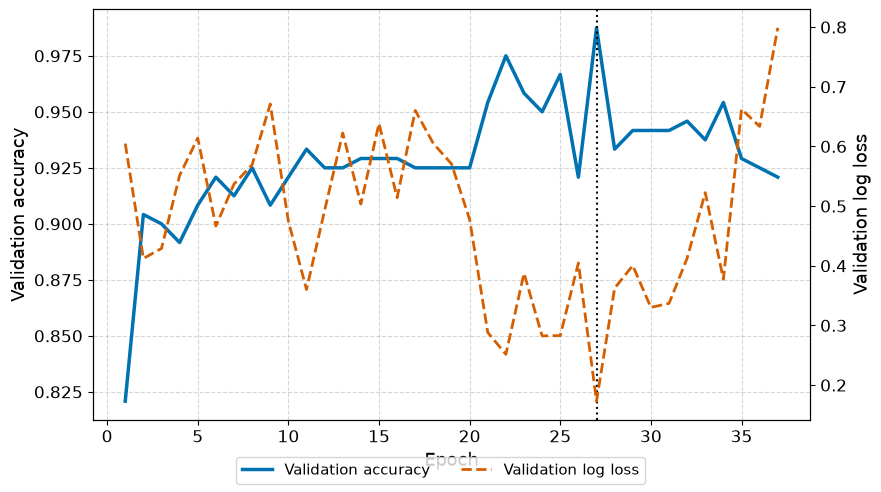

In [10]:
# Final configuration — Custom Transformer
chosen = select_best(transformer_search)
best_config = {"num_heads": int(chosen["num_heads"]), "num_blocks": int(chosen["num_blocks"]),
               "dropout": float(chosen["dropout"]), "learning_rate": float(chosen["learning_rate"])}
best_epoch = int(chosen["Best epoch"])
describe = (f"{best_config['num_blocks']} block(s), {best_config['num_heads']} head(s), ff 256, "
            f"dropout {best_config['dropout']}, learning rate {best_config['learning_rate']:g}, {best_epoch} epochs, GloVe")

final_model, transformer_final, refit_seconds = refit_on_train_val(best_config, best_epoch)
FINAL_MODEL = final_model


def transformer_predictor(text, model=final_model):
    return model(refit_vectorizer(np.array([text])), training=False).numpy()[0]


register("Custom Transformer", search_proba[chosen["Key"]], configuration=describe,
         why=selection_reason(transformer_search, chosen), parameters=final_model.count_params(),
         latency_ms=measure_latency(lambda i: transformer_predictor(texts[i])),
         predictor=transformer_predictor, fit_seconds=refit_seconds, proba_final=transformer_final)

# Curva de validation de la configuración elegida
history = pd.DataFrame(search_history[chosen["Key"]])
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(history["Epoch"], history["Validation accuracy"], color=ACCENT, linewidth=2.5, label="Validation accuracy")
ax2 = ax1.twinx()
ax2.plot(history["Epoch"], history["Validation log loss"], color=WARNING, linewidth=2, linestyle="--",
         label="Validation log loss")
ax1.axvline(best_epoch, color=INK, linestyle=":", linewidth=1.5)
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Validation accuracy")
ax2.set_ylabel("Validation log loss")
fig.legend(loc="lower center", ncol=2, fontsize=FONTSIZE - 2)
ax1.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 4.2 Ablaciones

Con la configuración elegida y el mismo protocolo (época elegida en validation, reentreno en train + validation):

- **Sin atención** (`num_blocks=0`): embeddings promediados + cabeza densa. ¿La atención aporta algo?
- **Sin GloVe** (`pretrained=False`): embeddings aleatorios. ¿Cuánto aporta el conocimiento previo de palabras?

In [11]:
ablations = {
    "Ablation: no attention": ({**best_config, "num_blocks": 0}, "average of embeddings + dense head (0 blocks)"),
    "Ablation: no GloVe": ({**best_config, "pretrained": False}, describe.replace("GloVe", "random embeddings")),
}
for name, (config, label) in ablations.items():
    model, proba, tracker, _ = fit_on_train(config)
    epochs = tracker.best["epoch"]
    refit_model, proba_final, seconds = refit_on_train_val(config, epochs)
    register(name, proba, configuration=f"{label}; {epochs} epochs",
             why="ablation of the chosen Custom Transformer configuration", parameters=refit_model.count_params(),
             latency_ms=measure_latency(lambda i, m=refit_model: m(refit_vectorizer(np.array([texts[i]])), training=False)),
             predictor=lambda text, m=refit_model: m(refit_vectorizer(np.array([text])), training=False).numpy()[0],
             fit_seconds=seconds, kind="Ablation", proba_final=proba_final)
    print()

running_summary()

Final configuration — Ablation: no attention
  Chosen:      average of embeddings + dense head (0 blocks); 19 epochs
  Why:         ablation of the chosen Custom Transformer configuration
  Validation:  accuracy 0.925, log loss 0.294 (training accuracy 1.000)
  Deployment:  45,284 parameters, 13.17 ms per command
  Test (refit on training + validation): accuracy 0.958, unseen commands 0.958, macro F1 0.959



Final configuration — Ablation: no GloVe
  Chosen:      1 block(s), 4 head(s), ff 256, dropout 0.2, learning rate 0.001, 27 epochs, random embeddings; 15 epochs
  Why:         ablation of the chosen Custom Transformer configuration
  Validation:  accuracy 0.917, log loss 0.682 (training accuracy 1.000)
  Deployment:  137,640 parameters, 40.28 ms per command
  Test (refit on training + validation): accuracy 0.946, unseen commands 0.946, macro F1 0.946



Model,Type,Validation accuracy,Test accuracy,Test accuracy (unseen),Test macro F1,Parameters,Latency (ms),Fit time (s)
Always predict 'TRANSFER_MONEY',Benchmark,0.125,0.125,0.125,0.028,0,0.00,—
Keyword rule,Benchmark,0.804,0.733,0.733,0.770,160,0.04,—
Custom Transformer,Model,0.988,0.988,0.988,0.987,"137,640",38.07,48.1
Ablation: no attention,Ablation,0.925,0.958,0.958,0.959,"45,284",13.17,8.9
Ablation: no GloVe,Ablation,0.917,0.946,0.946,0.946,"137,640",40.28,29.4


*(Interpretación después de correr.)*

### 4.3 Dónde se equivoca

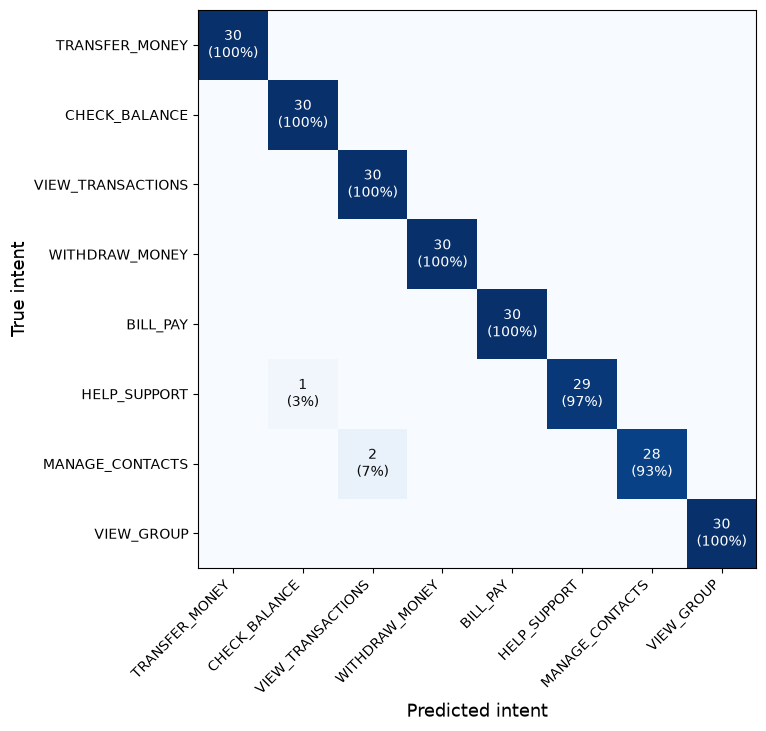

                   precision    recall  f1-score   support

   TRANSFER_MONEY      1.000     1.000     1.000        30
    CHECK_BALANCE      0.968     1.000     0.984        30
VIEW_TRANSACTIONS      0.938     1.000     0.968        30
   WITHDRAW_MONEY      1.000     1.000     1.000        30
         BILL_PAY      1.000     1.000     1.000        30
     HELP_SUPPORT      1.000     0.967     0.983        30
  MANAGE_CONTACTS      1.000     0.933     0.966        30
       VIEW_GROUP      1.000     1.000     1.000        30

         accuracy                          0.988       240
        macro avg      0.988     0.988     0.987       240
     weighted avg      0.988     0.988     0.987       240

3 errores en test


,text,intent,predicted,confidence
951,Show beneficiaries,MANAGE_CONTACTS,VIEW_TRANSACTIONS,0.996529
2628,Show beneficiaries quickly,MANAGE_CONTACTS,VIEW_TRANSACTIONS,0.996068
182,I have a complaint,HELP_SUPPORT,CHECK_BALANCE,0.540117


In [12]:
pred = predict_labels(transformer_final)
confusion = confusion_matrix(y[test_idx], pred[test_idx], labels=range(len(CLASSES)))
share = confusion / confusion.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        if confusion[i, j]:
            ax.text(j, i, f"{confusion[i, j]}\n({share[i, j]:.0%})", ha="center", va="center",
                    fontsize=FONTSIZE - 3, color="white" if share[i, j] > 0.5 else INK)
ax.set_xticks(range(len(CLASSES)))
ax.set_xticklabels(CLASSES, rotation=45, ha="right", fontsize=FONTSIZE - 3)
ax.set_yticks(range(len(CLASSES)))
ax.set_yticklabels(CLASSES, fontsize=FONTSIZE - 3)
ax.set_xlabel("Predicted intent")
ax.set_ylabel("True intent")
plt.tight_layout()
plt.show()

print(classification_report(y[test_idx], pred[test_idx], target_names=CLASSES, digits=3))
errors = dat.iloc[test_idx].assign(predicted=[CLASSES[k] for k in pred[test_idx]],
                                   confidence=transformer_final[test_idx].max(axis=1))
errors = errors[pred[test_idx] != y[test_idx]][["text", "intent", "predicted", "confidence"]]
print(f"{len(errors)} errores en test")
display(errors.sort_values("confidence", ascending=False))

## 5. La compuerta de confianza

### 5.1 Calibración (temperature scaling)

Igual que Ricardo: se divide el log de las probabilidades por una temperatura $T$ antes del softmax. $T$ se ajusta minimizando la log loss en los comandos soportados de validation, con la copia de **solo train**, y se aplica sin cambios a la copia **reentrenada**. No cambia la intención predicha, solo la confianza. Los benchmarks (0/1 o uniforme) quedan como están.

Model,Temperature,Val log loss (raw),Val log loss (calibrated),Val ECE (raw),Val ECE (calibrated),"Mean confidence, supported (calibrated)","Mean confidence, unsupported (calibrated)"
Custom Transformer,2.302,0.173,0.114,0.016,0.019,0.969,0.756
Ablation: no attention,1.444,0.294,0.263,0.067,0.069,0.923,0.570
Ablation: no GloVe,2.745,0.682,0.364,0.071,0.080,0.896,0.610


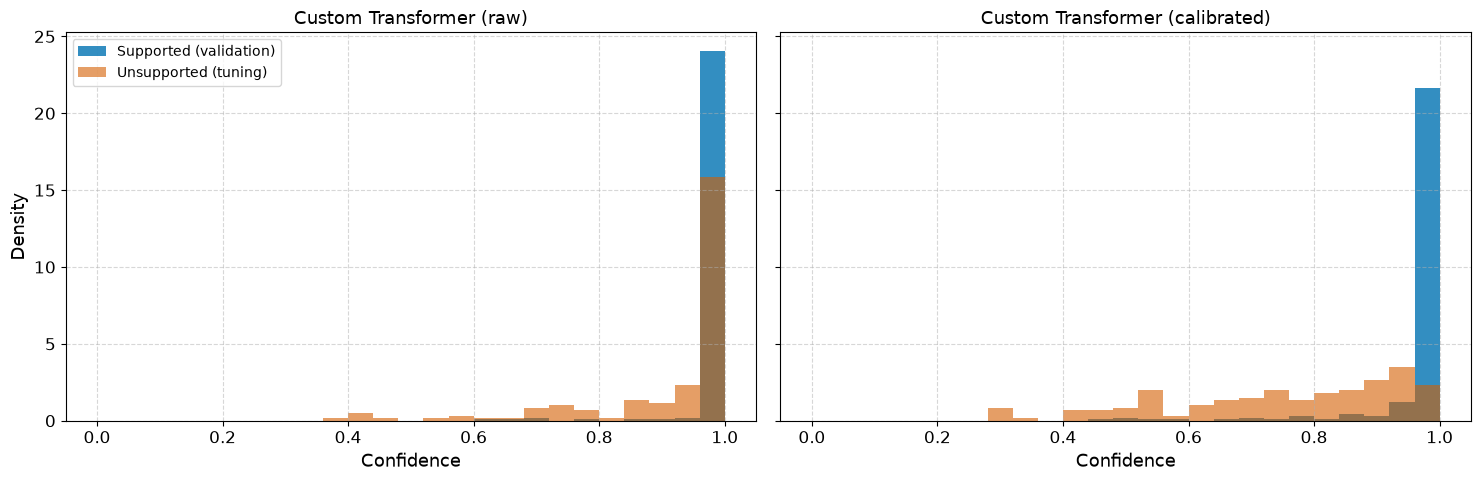

In [13]:
def apply_temperature(proba, temperature):
    logits = np.log(np.clip(proba, 1e-12, 1.0)) / temperature
    logits -= logits.max(axis=1, keepdims=True)
    exponentiated = np.exp(logits)
    return exponentiated / exponentiated.sum(axis=1, keepdims=True)


def fit_temperature(proba):
    result = minimize_scalar(lambda log_t: log_loss_on(apply_temperature(proba, np.exp(log_t)), val_idx),
                             bounds=(-4, 4), method="bounded")
    return float(np.exp(result.x))


def expected_calibration_error(proba, subset, bins=10):
    confidence = proba[subset].max(axis=1)
    correct = proba[subset].argmax(axis=1) == y[subset]
    edges = np.linspace(0, 1, bins + 1)
    error = 0.0
    for low, high in zip(edges[:-1], edges[1:]):
        in_bin = (confidence > low) & (confidence <= high)
        if in_bin.any():
            error += in_bin.mean() * abs(correct[in_bin].mean() - confidence[in_bin].mean())
    return error


TEMPERATURE, GATE_PROBA, GATE_PROBA_FINAL = {}, {}, {}
calibration_rows = []
for name, finalist in FINALISTS.items():
    raw_proba = finalist["proba"]
    if finalist["kind"] == "Benchmark":
        TEMPERATURE[name], GATE_PROBA[name], GATE_PROBA_FINAL[name] = 1.0, raw_proba, finalist["proba_final"]
        continue
    temperature = fit_temperature(raw_proba)
    calibrated = apply_temperature(raw_proba, temperature)
    TEMPERATURE[name], GATE_PROBA[name] = temperature, calibrated
    GATE_PROBA_FINAL[name] = apply_temperature(finalist["proba_final"], temperature)
    calibration_rows.append({
        "Model": name, "Temperature": temperature,
        "Val log loss (raw)": log_loss_on(raw_proba, val_idx), "Val log loss (calibrated)": log_loss_on(calibrated, val_idx),
        "Val ECE (raw)": expected_calibration_error(raw_proba, val_idx),
        "Val ECE (calibrated)": expected_calibration_error(calibrated, val_idx),
        "Mean confidence, supported (calibrated)": calibrated[val_idx].max(axis=1).mean(),
        "Mean confidence, unsupported (calibrated)": calibrated[unk_tune_idx].max(axis=1).mean(),
    })

display(pd.DataFrame(calibration_rows).style.format(
    {c: "{:.3f}" for c in calibration_rows[0] if c != "Model"}).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, (label, proba) in zip(axes, [("raw", FINALISTS["Custom Transformer"]["proba"]),
                                     ("calibrated", GATE_PROBA["Custom Transformer"])]):
    confidence = proba.max(axis=1)
    bins = np.linspace(0, 1, 26)
    ax.hist(confidence[val_idx], bins=bins, color=ACCENT, alpha=0.8, density=True, label="Supported (validation)")
    ax.hist(confidence[unk_tune_idx], bins=bins, color=WARNING, alpha=0.6, density=True, label="Unsupported (tuning)")
    ax.set_title(f"Custom Transformer ({label})", fontsize=FONTSIZE)
    ax.set_xlabel("Confidence")
    ax.grid(True, linestyle="--", alpha=0.5)
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=FONTSIZE - 3)
plt.tight_layout()
plt.show()

### 5.2 Un umbral para cada modelo

Mismos costos ilustrativos y misma regla de Ricardo: el umbral que maximiza el valor en validation + 150 no soportados de ajuste (probabilidades calibradas de la copia de solo train).

In [14]:
COMMANDS_PER_DAY = 5_000
DAYS_PER_YEAR = 365
SHARE_UNSUPPORTED = 0.10
VALUE_CORRECT = 0.10
COST_FALLBACK = 0.05
COST_WRONG_INFO = 0.50
COST_WRONG_MONEY = 5.00

MONEY_MOVING_IDS = [CLASSES.index(c) for c in MONEY_MOVING]
THRESHOLDS = np.round(np.concatenate([np.arange(0.0, 0.95, 0.005), np.arange(0.95, 1.0, 0.001)]), 4)


def gate_outcomes(proba, subset, threshold):
    p, truth = proba[subset], y[subset]
    confidence, pred = p.max(axis=1), predict_labels(p)
    accept = (confidence >= threshold) & (pred != ABSTAIN)
    supported, unsupported = truth >= 0, truth < 0
    money = np.isin(pred, MONEY_MOVING_IDS)
    wrong = supported & accept & (pred != truth)
    return {
        "Routed correctly": (supported & accept & (pred == truth)).sum() / supported.sum(),
        "Fallback": (supported & ~accept).sum() / supported.sum(),
        "Wrong workflow": wrong.sum() / supported.sum(),
        "Wrong money workflow": (wrong & money).sum() / supported.sum(),
        "Unsupported rejected": (unsupported & ~accept).sum() / unsupported.sum(),
        "Unsupported accepted": (unsupported & accept).sum() / unsupported.sum(),
        "Unsupported into money workflow": (unsupported & accept & money).sum() / unsupported.sum(),
    }


def value_per_command(o, cost_wrong_money=None):
    cost_money = COST_WRONG_MONEY if cost_wrong_money is None else cost_wrong_money
    supported = (o["Routed correctly"] * VALUE_CORRECT - o["Fallback"] * COST_FALLBACK
                 - (o["Wrong workflow"] - o["Wrong money workflow"]) * COST_WRONG_INFO
                 - o["Wrong money workflow"] * cost_money)
    unsupported = -((o["Unsupported accepted"] - o["Unsupported into money workflow"]) * COST_WRONG_INFO
                    + o["Unsupported into money workflow"] * cost_money)
    return (1 - SHARE_UNSUPPORTED) * supported + SHARE_UNSUPPORTED * unsupported


def choose_threshold(proba, cost_wrong_money=None):
    values = [value_per_command(gate_outcomes(proba, gate_val_idx, t), cost_wrong_money) for t in THRESHOLDS]
    return float(THRESHOLDS[int(np.argmax(values))]), float(np.max(values))


gate_rows = []
for name in FINALISTS:
    raw_threshold, raw_value = choose_threshold(FINALISTS[name]["proba"])
    threshold, value = choose_threshold(GATE_PROBA[name])
    o = gate_outcomes(GATE_PROBA[name], gate_val_idx, threshold)
    gate_rows.append({"Model": name, "Threshold (raw)": raw_threshold,
                      "Validation value / 1,000 (raw)": 1000 * raw_value, "Temperature": TEMPERATURE[name],
                      "Threshold": threshold, **{k: o[k] for k in ["Routed correctly", "Fallback", "Wrong workflow",
                                                                   "Wrong money workflow", "Unsupported accepted"]},
                      "Validation value / 1,000": 1000 * value, "Latency (ms)": FINALISTS[name]["latency_ms"]})
gate_results = pd.DataFrame(gate_rows)
percent = ["Routed correctly", "Fallback", "Wrong workflow", "Wrong money workflow", "Unsupported accepted"]
display(gate_results.style.format({**{c: "{:.1%}" for c in percent}, "Threshold (raw)": "{:.3f}", "Threshold": "{:.3f}",
                                   "Temperature": "{:.2f}", "Validation value / 1,000 (raw)": "${:,.1f}",
                                   "Validation value / 1,000": "${:,.1f}", "Latency (ms)": "{:.2f}"}).hide(axis="index"))

Model,Threshold (raw),"Validation value / 1,000 (raw)",Temperature,Threshold,Routed correctly,Fallback,Wrong workflow,Wrong money workflow,Unsupported accepted,"Validation value / 1,000",Latency (ms)
Always predict 'TRANSFER_MONEY',0.000,"$-4,426.2",1.00,0.000,12.5%,0.0%,87.5%,87.5%,100.0%,"$-4,426.2",0.00
Keyword rule,0.000,$-477.5,1.00,0.000,80.4%,7.1%,12.5%,9.6%,42.7%,$-477.5,0.04
Custom Transformer,0.999,$56.8,2.30,0.958,85.8%,13.3%,0.8%,0.0%,9.3%,$62.8,38.07
Ablation: no attention,0.958,$55.9,1.44,0.895,77.1%,22.9%,0.0%,0.0%,4.7%,$56.7,13.17
Ablation: no GloVe,0.999,$56.3,2.75,0.900,77.9%,22.1%,0.0%,0.0%,4.7%,$57.9,40.28


## 6. Comparación final en test

Mismas columnas que `tables/final_comparison_test.csv` de Ricardo: cada modelo con su umbral de validation aplicado sin cambios a la copia reentrenada (calibrada) sobre test + 150 no soportados reservados. Si el archivo de Ricardo está en `reports/ricardo_v5_final_comparison_test.csv`, se agrega su fila de DistilBERT para tener la tabla del equipo completa.

In [15]:
final_rows = []
for name, finalist in FINALISTS.items():
    threshold = float(gate_results.set_index("Model").loc[name, "Threshold"])
    o = gate_outcomes(GATE_PROBA_FINAL[name], gate_test_idx, threshold)
    value = value_per_command(o)
    final_rows.append({"Model": name, **test_scores(finalist["proba_final"]),
                       "Parameters": finalist["parameters"], "Latency (ms)": finalist["latency_ms"],
                       "Threshold": threshold, "Correct": o["Routed correctly"], "Wrong": o["Wrong workflow"],
                       "Fallback": o["Fallback"], "Wrong money flow": o["Wrong money workflow"],
                       "Unsupported accepted": o["Unsupported accepted"],
                       "Unsupported into money flow": o["Unsupported into money workflow"],
                       "Test value / 1,000": 1000 * value, "Annual value": value * COMMANDS_PER_DAY * DAYS_PER_YEAR})
final_comparison = pd.DataFrame(final_rows)
final_comparison.to_csv(REPORTS / "final_comparison_test_felipe_v5.csv", index=False)


def as_ricardo_table(frame):
    out = frame.copy()
    for c in ["Test accuracy", "Test accuracy (unseen)", "Test macro F1", "Threshold"]:
        out[c] = out[c].map(lambda v: f"{v:.3f}")
    for c in ["Correct", "Wrong", "Fallback", "Wrong money flow", "Unsupported accepted", "Unsupported into money flow"]:
        out[c] = out[c].map(lambda v: f"{v:.1%}")
    out["Parameters"] = out["Parameters"].map(lambda v: f"{v:,.0f}")
    out["Latency (ms)"] = out["Latency (ms)"].map(lambda v: f"{v:.2f}")
    out["Test value / 1,000"] = out["Test value / 1,000"].map(lambda v: f"${v:,.1f}")
    out["Annual value"] = out["Annual value"].map(lambda v: f"${v:,.0f}")
    return out


team_table = as_ricardo_table(final_comparison)
ricardo_file = REPORTS / "ricardo_v5_final_comparison_test.csv"
if ricardo_file.exists():
    ricardo = pd.read_csv(ricardo_file, dtype=str)
    team_table = pd.concat([ricardo[ricardo["Model"].str.contains("DistilBERT")], team_table[team_table["Model"].isin(
        ["Custom Transformer", "Ablation: no attention", "Ablation: no GloVe"])]], ignore_index=True)
    team_table = pd.concat([as_ricardo_table(final_comparison[final_comparison["Model"].str.startswith(("Always", "Keyword"))]),
                            team_table], ignore_index=True)
display(team_table.style.hide(axis="index"))

Model,Test accuracy,Test accuracy (unseen),Test macro F1,Parameters,Latency (ms),Threshold,Correct,Wrong,Fallback,Wrong money flow,Unsupported accepted,Unsupported into money flow,"Test value / 1,000",Annual value
Always predict 'TRANSFER_MONEY',0.125,0.125,0.028,0,0.00,0.000,12.5%,87.5%,0.0%,87.5%,100.0%,100.0%,"$-4,426.2","$-8,077,906"
Keyword rule,0.733,0.733,0.770,160,0.04,0.000,73.3%,11.7%,15.0%,8.8%,38.7%,16.7%,$-442.0,"$-806,574"
Fine-tuned DistilBERT,0.992,0.992,0.992,"66,959,624",5.55,0.940,94.2%,0.0%,5.8%,0.0%,12.0%,0.0%,$76.1,"$138,928"
Custom Transformer,0.988,0.988,0.987,"137,640",38.07,0.958,93.3%,0.0%,6.7%,0.0%,15.3%,1.3%,$67.3,"$122,883"
Ablation: no attention,0.958,0.958,0.959,"45,284",13.17,0.895,82.5%,0.8%,16.7%,0.0%,2.0%,0.0%,$62.0,"$113,150"
Ablation: no GloVe,0.946,0.946,0.946,"137,640",40.28,0.900,84.6%,0.4%,15.0%,0.0%,14.0%,4.7%,$39.5,"$72,088"


*(Interpretación después de correr.)*

## 7. Probarlo con frases nuevas

La función de enrutamiento con el Transformer reentrenado: probabilidades calibradas con su temperatura y su umbral de validation.

In [16]:
T_TRANSFORMER = TEMPERATURE["Custom Transformer"]
THRESHOLD_TRANSFORMER = float(gate_results.set_index("Model").loc["Custom Transformer", "Threshold"])


def route(command):
    proba = apply_temperature(transformer_predictor(command)[None, :], T_TRANSFORMER)[0]
    top = int(proba.argmax())
    action = f"open {CLASSES[top]}" if proba[top] >= THRESHOLD_TRANSFORMER else "fallback: clarification / help"
    return CLASSES[top], float(proba[top]), action


print(f"Custom Transformer (T = {T_TRANSFORMER:.3f}, threshold = {THRESHOLD_TRANSFORMER:.3f})\n")
for command in ["Send 20 to my mum", "transfer didn't go through", "how much do I have",
                "show what I withdrew last week", "pay fiji water", "who paid into the church group",
                "book me a taxi", "what's the weather tomorrow"]:
    intent, confidence, action = route(command)
    print(f"{command:35s} -> {intent:18s} {confidence:6.1%}   {action}")

Custom Transformer (T = 2.302, threshold = 0.958)

Send 20 to my mum                   -> TRANSFER_MONEY      99.7%   open TRANSFER_MONEY
transfer didn't go through          -> TRANSFER_MONEY      98.9%   open TRANSFER_MONEY
how much do I have                  -> CHECK_BALANCE       99.7%   open CHECK_BALANCE
show what I withdrew last week      -> VIEW_TRANSACTIONS   99.0%   open VIEW_TRANSACTIONS
pay fiji water                      -> BILL_PAY            71.9%   fallback: clarification / help


who paid into the church group      -> VIEW_GROUP          99.8%   open VIEW_GROUP
book me a taxi                      -> MANAGE_CONTACTS     93.7%   fallback: clarification / help
what's the weather tomorrow         -> VIEW_GROUP          61.7%   fallback: clarification / help
